# 3 — Train Baseline Classifier

## Objective
Train a baseline logistic-regression model to classify pork rasher package images as **PASS** or **FAIL** from six precomputed RGB colour statistics. This model provides a point of comparison for future feature-engineering experiments.

## Input
- `../data/processed/train_features.csv`: training-image features and their class labels.

## Workflow
1. Make the required Python packages available and import them.
2. Read the training feature table.
3. Select mean red/green/blue intensities and their standard deviations as predictors, and `label` as the target.
4. Configure and fit a class-weighted logistic-regression classifier.
5. Save the fitted model for use in Notebook 04.

## Output
- `../models/baseline_logistic_regression.joblib`: serialised fitted classifier.

**Dataset note:** This notebook uses the pre-existing training dataset; it does not create a new train/validation split or export split assignments. The `random_state` controls supported randomness within the estimator, not which images are assigned to training.

### Setup and dependencies
Install the packages needed to load tabular data and train a classifier.

In [7]:
# Import the table-handling, classifier, and evaluation utilities.
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

### Load training features
Read the CSV produced by the earlier feature-extraction workflow.

In [8]:
# Load one row of precomputed colour features per training image.
features_df = pd.read_csv("../data/processed/train_features.csv")

### Select predictors and labels
The six RGB statistics form the inputs (`X_train`); `label` is the outcome the classifier learns to predict.

In [9]:
# Select six per-image colour measurements as model inputs.
# Keep labels separate so they are not accidentally included as predictors.
#Define inputs
X_train = features_df[
    [
        "mean_red",
        "mean_green",
        "mean_blue",
        "std_red",
        "std_green",
        "std_blue"
    ]
]

y_train = features_df["label"]

### Configure the model
Use a constant seed for reproducibility and balanced class weights to account for unequal class frequencies.

In [10]:
# Fix the model seed so supported stochastic operations are repeatable.
RANDOM_SEED = 67

In [11]:
# Weight each class inversely to its frequency in the training data.
# Increase the iteration allowance to help the optimiser converge.
model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=RANDOM_SEED
)

### Fit the baseline classifier
Estimate the model parameters using the training features and labels.

In [12]:
# Fit logistic regression using the existing training partition only.
model.fit(X_train, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",67
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

## Evaluate the fitted model on the training data

Report in-sample whole-image classification performance using the same features and labels used to fit the model. Macro F1 averages the F1 scores equally across classes. Accuracy is the fraction classified correctly; balanced accuracy is the mean recall across classes. These metrics are unweighted, even when training uses class or sample weights.

The confusion matrix has true labels as rows and predicted labels as columns. These training results help assess model fit and compare against validation results; they do not measure performance on unseen data. Prediction reuses the fitted model and any fitted preprocessing without refitting.


TRAINING METRICS (whole-image, in-sample)
Macro F1:          0.5286
Accuracy:          57.33%
Balanced accuracy: 60.15%


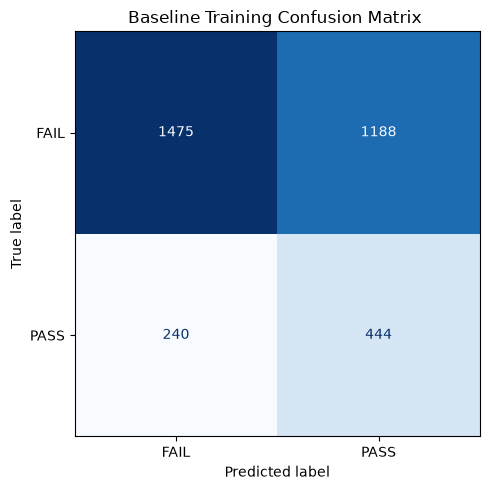

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Predict the original training examples using the already-fitted model.
y_train_pred = model.predict(X_train)
train_class_labels = ["FAIL", "PASS"]

train_macro_f1 = f1_score(
    y_train, y_train_pred,
    labels=train_class_labels, average="macro", zero_division=0
)
train_accuracy = accuracy_score(y_train, y_train_pred)
train_balanced_accuracy = balanced_accuracy_score(y_train, y_train_pred)

print("TRAINING METRICS (whole-image, in-sample)")
print(f"Macro F1:          {train_macro_f1:.4f}")
print(f"Accuracy:          {train_accuracy:.2%}")
print(f"Balanced accuracy: {train_balanced_accuracy:.2%}")

# Plot the confusion matrix (rows = true, columns = predicted).
train_cm = confusion_matrix(
    y_train, y_train_pred, labels=train_class_labels
)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=train_cm,
    display_labels=train_class_labels,
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False,
)

ax.set_title("Baseline Training Confusion Matrix ")
plt.tight_layout()
plt.show()

### Save the trained model
Serialise the fitted estimator so Notebook 04 can load and evaluate the same model.

In [14]:
# Import tools for saving Python objects and constructing file paths.
import joblib
from pathlib import Path

In [15]:
# Ensure the model output directory exists, then save the trained estimator.
# This does not save or change dataset assignments.
PROJECT_ROOT = Path("..")
MODEL_DIR = PROJECT_ROOT / "models"

MODEL_DIR.mkdir(exist_ok=True)

MODEL_PATH = MODEL_DIR / "baseline_logistic_regression.joblib"

joblib.dump(model, MODEL_PATH)

print("Model saved to:", MODEL_PATH)

Model saved to: ..\models\baseline_logistic_regression.joblib


## Final training performance summary

Image-level PASS/FAIL metrics using the labels and predictions produced above. Run the preceding evaluation cells in this notebook before running this summary. Values are on a 0–1 scale and displayed to four decimal places; the summary table retains full numeric precision.

These are in-sample training results, not validation or held-out test performance.


In [16]:
# Reuse existing labels and predictions; do not refit or reload a model.
import pandas as _summary_pd
from IPython.display import display as _summary_display
from sklearn.metrics import (
    accuracy_score as _summary_accuracy,
    balanced_accuracy_score as _summary_balanced_accuracy,
    f1_score as _summary_f1,
    recall_score as _summary_recall,
)


def _make_performance_summary(actual, predicted, fail_label, pass_label,
                              fail_name="FAIL", pass_name="PASS"):
    """Return numeric metrics with explicit positive/negative class labels."""
    return _summary_pd.DataFrame({
        "Metric": [
            "Accuracy", "Balanced accuracy", "Macro F1",
            f"{fail_name} recall", f"{pass_name} recall",
        ],
        "Value": [
            _summary_accuracy(actual, predicted),
            _summary_balanced_accuracy(actual, predicted),
            _summary_f1(
                actual, predicted, labels=[fail_label, pass_label],
                average="macro", zero_division=0,
            ),
            _summary_recall(
                actual, predicted, pos_label=fail_label, zero_division=0,
            ),
            _summary_recall(
                actual, predicted, pos_label=pass_label, zero_division=0,
            ),
        ],
    }).set_index("Metric")


# Image-level training metrics.
summary_table = _make_performance_summary(
    y_train,
    y_train_pred,
    fail_label="FAIL", pass_label="PASS",
)
print("TRAINING SUMMARY — IMAGE LEVEL")
_summary_display(summary_table.round(4))


TRAINING SUMMARY — IMAGE LEVEL


,Value
Metric,
Accuracy,0.5733
Balanced accuracy,0.6015
Macro F1,0.5286
FAIL recall,0.5539
PASS recall,0.6491
